In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb


In [2]:
df = pd.read_csv('Social_Network_Ads.csv')

In [11]:
df.sample(5)

,Age,EstimatedSalary,Purchased
361,53,34000,1
366,58,47000,1
81,39,42000,0
119,41,59000,0
282,37,70000,1


# 1. Train-Test Split

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(df.drop('Purchased', axis= 1),
                                                   df['Purchased'], test_size=.3,
                                                   random_state= 0)

X_train.shape, X_test.shape

((280, 2), (120, 2))

# 2. Standard Scaler

In [15]:
from sklearn.preprocessing import StandardScaler

In [16]:
scaler = StandardScaler()

In [18]:
scaler.fit(X_train)

,copy,True
,with_mean,True
,with_std,True


In [19]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
scaler.mean_

array([3.78642857e+01, 6.98071429e+04])

In [22]:

X_train

,Age,EstimatedSalary
92,26,15000
223,60,102000
234,38,112000
232,40,107000
377,42,53000
...,...,...
323,48,30000
192,29,43000
117,36,52000
47,27,54000


In [27]:
# What we got was series but we convert them to DataFrame

X_train_scaled
x_train= pd.DataFrame(data= X_train_scaled, columns=X_train.columns)
x_train

,Age,EstimatedSalary
0,-1.163172,-1.584970
1,2.170181,0.930987
2,0.013305,1.220177
3,0.209385,1.075582
4,0.405465,-0.486047
...,...,...
275,0.993704,-1.151185
276,-0.869053,-0.775237
277,-0.182774,-0.514966
278,-1.065133,-0.457127


In [37]:
# Scaled train set

np.round(x_train.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


In [38]:
# Raw train set

np.round(X_train.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [35]:
x_test = pd.DataFrame(data= X_test_scaled, columns= X_test.columns)
np.round(x_test.describe(), 1)

,Age,EstimatedSalary
count,120.0,120.0
mean,-0.1,-0.0
std,1.1,1.0
min,-1.9,-1.6
25%,-1.0,-0.7
50%,-0.2,-0.2
75%,0.7,0.5
max,2.2,2.3


# Effect of scaling

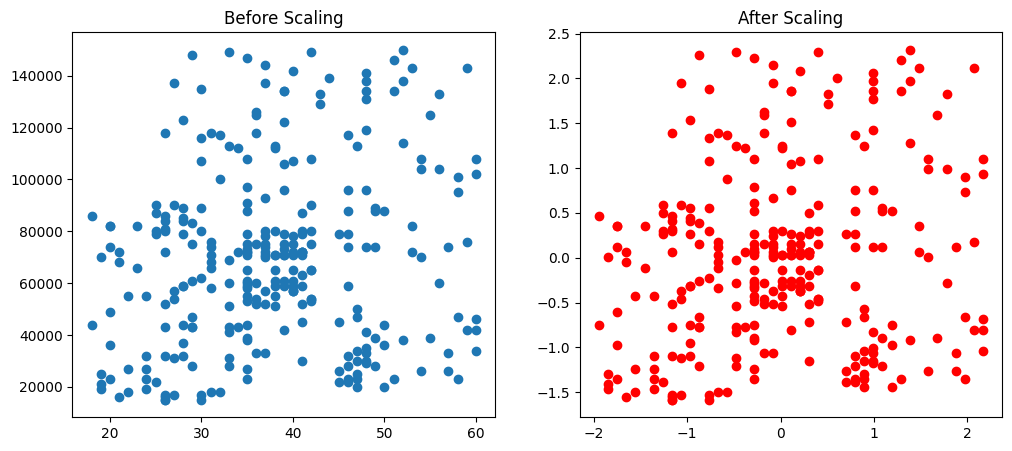

In [41]:
fig, (ax1, ax2) = plt.subplots(ncols= 2, figsize= (12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(x_train['Age'], x_train['EstimatedSalary'], color= "Red")
ax2.set_title("After Scaling")

plt.show()

In [42]:
# The above graph though looks the same but just value scale is changed, look for values on x and y axis

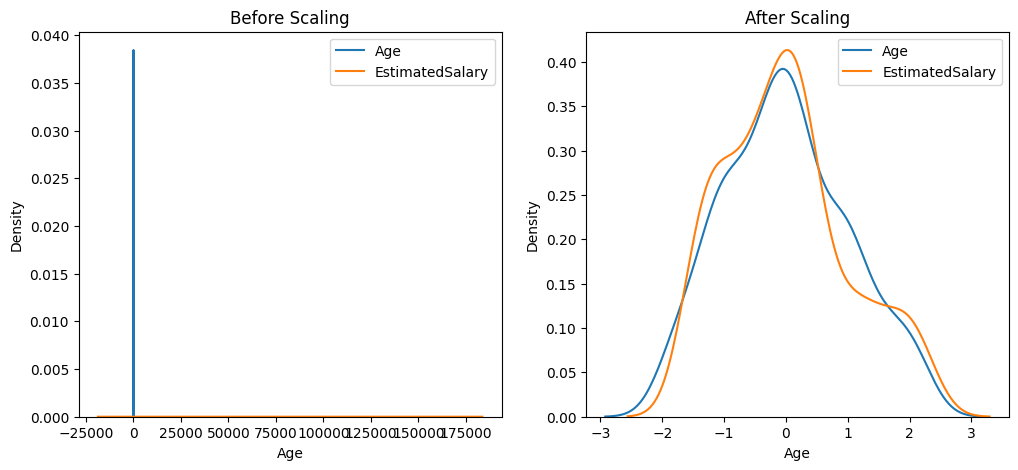

In [52]:
#Now plotting KDEplot to see changes

fig, (ax1, ax2) = plt.subplots(ncols= 2, figsize= (12, 5))

ax1.set_title("Before Scaling")
sb.kdeplot(X_train['Age'], ax= ax1, label= "Age")
sb.kdeplot(X_train['EstimatedSalary'], ax= ax1, label= "EstimatedSalary")
ax1.legend()

ax2.set_title("After Scaling")
sb.kdeplot(x_train['Age'], ax= ax2, label= "Age")
sb.kdeplot(x_train['EstimatedSalary'], ax= ax2, label= "EstimatedSalary")
ax2.legend()

plt.show()

In [53]:
# Now above grapgh shows after scaling both col's Age and Salary are on same scale

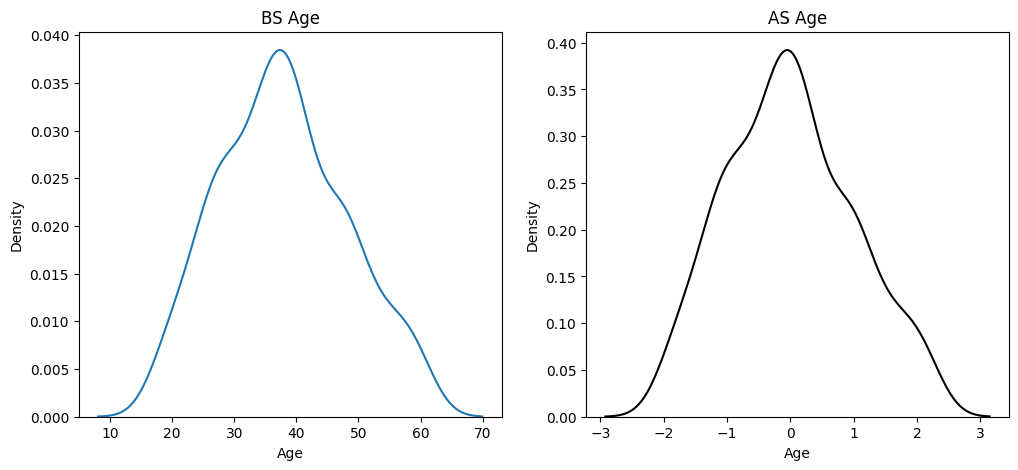

In [57]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize= (12,5))

ax1.set_title("BS Age")
sb.kdeplot(X_train['Age'], ax= ax1)

ax2.set_title("AS Age")
sb.kdeplot(x_train['Age'], ax= ax2, color= "Black")


plt.show()